# **OpenMS-Powerpoint-Banner-Script**

Success! Content-slide accent strip saved as '../banners/openms_ppt_content_strip.png' (1920x400 px).


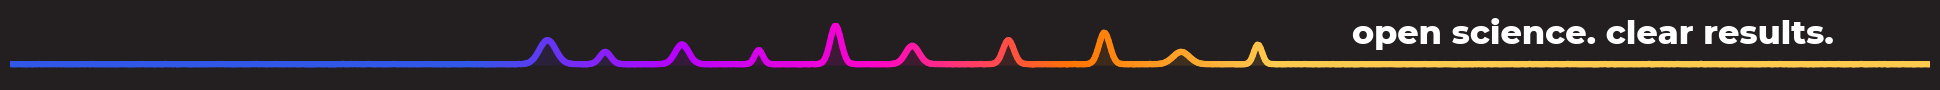

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.font_manager import FontProperties
# ==============================================================================
# 1. FONT CONFIGURATION (PUT YOUR PATH HERE)
# ==============================================================================
FONT_PATH = "../fonts/Montserrat/static/Montserrat-ExtraBold.ttf"
if os.path.exists(FONT_PATH):
    font_header = FontProperties(fname=FONT_PATH)
else:
    print(f"[WARNING] Font file not found at '{FONT_PATH}'. Falling back to system bold font.")
    font_header = FontProperties(family="sans-serif", weight="bold")
# ==============================================================================
# 2. BRAND DESIGN SPECS
# ==============================================================================
bg_color = '#231f20'  # Official Logo Black
brand_gradient = ['#3157e9', '#b503ff', '#ff03cb', '#ff7501', '#ffcb4f']  # Core palette
# Adjust this value to shift everything left or right (Higher value = further left)
X_SHIFT = 3.2
# ==============================================================================
# 3. CANVAS & PLOT SETUP
# Compact accent-strip banner for content slides.
# Full slide width (1920px) but much shorter height (400px) -> ~4.8:1 strip,
# meant to sit along the top or bottom edge of a content slide, not fill it.
# ==============================================================================
dpi = 100
fig, ax = plt.subplots(figsize=(19.2, 0.7), dpi=dpi)
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.axis('off')
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
cmap = LinearSegmentedColormap.from_list('openms_gradient', brand_gradient, N=256)
# ==============================================================================
# 4. GENERATE DATA (Mass Spec Spectrum Peaks - Shifted Left)
# ==============================================================================
x = np.linspace(0, 10, 1200)
y = np.random.normal(0.012, 0.002, len(x))
peaks = [
    (6.0 - X_SHIFT, 0.55, 0.06), (6.3 - X_SHIFT, 0.28, 0.04), (6.7 - X_SHIFT, 0.45, 0.05),
    (7.1 - X_SHIFT, 0.32, 0.03), (7.5 - X_SHIFT, 0.88, 0.04), (7.9 - X_SHIFT, 0.42, 0.05),
    (8.4 - X_SHIFT, 0.55, 0.04), (8.9 - X_SHIFT, 0.72, 0.04), (9.3 - X_SHIFT, 0.28, 0.06),
    (9.7 - X_SHIFT, 0.45, 0.03)
]
for pos, height, width in peaks:
    y += height * np.exp(-((x - pos) / width) ** 2)
y = np.clip(y, 0, None)
start_gradient_x = 5.6 - X_SHIFT
end_gradient_x = 9.8 - X_SHIFT
for i in range(len(x) - 1):
    norm_val = (x[i] - start_gradient_x) / (end_gradient_x - start_gradient_x)
    color = cmap(np.clip(norm_val, 0, 1))
    ax.plot(x[i:i+2], y[i:i+2], color=color, lw=4.5, solid_capstyle='round')
    ax.fill_between(x[i:i+2], 0, y[i:i+2], color=color, alpha=0.05)
# ==============================================================================
# 5. TYPOGRAPHY INJECTION
# Text moved further left and down so it sits clear of the peaks, allowing
# the overall banner height to shrink without the two colliding.
# ==============================================================================
text_color = '#ffffff'
text_x = 9.5   # near the right edge (xlim spans 0-10)
scaled_fontsize = 24
# Single line, right-aligned, sitting above the peaks
ax.text(
    x=text_x,
    y=0.7,
    s="open science. clear results.",
    color=text_color,
    fontproperties=font_header,
    fontsize=scaled_fontsize,
    va='center',
    ha='right'
)
# ==============================================================================
# 6. EXPORT
# ==============================================================================
ax.set_xlim(0, 10)
ax.set_ylim(-0.35, 1.25)
output_filename = '../banners/openms_ppt_content_strip.png'
plt.savefig(output_filename, facecolor=fig.get_facecolor(), edgecolor='none', dpi=dpi)
#plt.close()
print(f"Success! Content-slide accent strip saved as '{output_filename}' (1920x400 px).")

---

#### **Versions**

In [2]:
import sys

# The specific libraries imported in your banner script
libs = ['numpy', 'matplotlib']

for lib in libs:
    try:
        mod = sys.modules.get(lib) or __import__(lib)
        print(f"{lib:12} : {getattr(mod, '__version__', 'unknown')}")
    except ImportError:
        print(f"{lib:12} : Not found")

numpy        : 2.2.6
matplotlib   : 3.10.3
